| Technological Institute of the Philippines | Quezon City - Computer Engineering |
|-------------------------------------------|------------------------------------|
| **Course Code:** | CPE 027 |
| **Code Title:** | Digital Signal Processing and Applications |
| **1st Semester** | AY 2026-2027 |
| **ACTIVITY NO. 12** | **Application for Speech Processing** |
| **Name:** | Pascual, Ken Leonard |
| **Section:** | CPE41S2 |
| **Date Performed:** | 16 October 2026 |
| **Date Submitted:** | 16 October 2026 |
| **Instructor:** | Engr. Jimlord M. Quejado |

## 1. Objectives

This activity aims to apply the various signal manipulation techniques for image analysis and
processing.

## 2. Intended Learning Outcomes (ILOs)
After completion of this activity, the students should be able to:

1. Develop a program that will detect the outline of the image

## 3. Discussion


Images are a description of how a parameter varies over a surface. For example, standard
visual images result from light intensity variations across a two-dimensional plane. However,
light is not the only parameter used in scientific imaging. For example, an image can be
formed of the temperature of an integrated circuit, blood velocity in a patient's artery, x-ray
emission from a distant galaxy, ground motion during an earthquake, etc. These exotic
images are usually converted into conventional pictures (i.e., light images), so that they can
be evaluated by the human eye. This first chapter on image processing describes how digital
images are formed and presented to human observers.
Edge detection is a crucial step in image analysis, used in tasks like object detection, image
segmentation, and feature extraction. The workflow involves capturing the image,
preprocessing it, applying an edge detection algorithm, and visualizing or analyzing the
results. The Canny edge detection algorithm is one of the most commonly used methods due
to its effectiveness in producing clean and accurate edges.

## 4. Resources
The activity will require the following software, tools and equipment:
* IDE or any online code editor
* Attached Image files


## 5. Directions:

### 1. Load the image and convert it into grayscale

#### Import libraries

In [29]:
import cv2
import matplotlib.pyplot as plt

IMAGE = "images/Cars403.png"  # chosen image
OUT = "ouptut"               # folder for the processed images

#### Import data

In [30]:
img = cv2.imread(IMAGE)                        # BGR, uint8
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)  # single intensity channel

print("image shape:", img.shape)
print("gray shape :", gray.shape)

image shape: (320, 400, 3)
gray shape : (320, 400)


The chosen image from this activity is **Cars403.png** from te Car License Plate Detection [dataset](https://www.kaggle.com/datasets/andrewmvd/car-plate-detection)

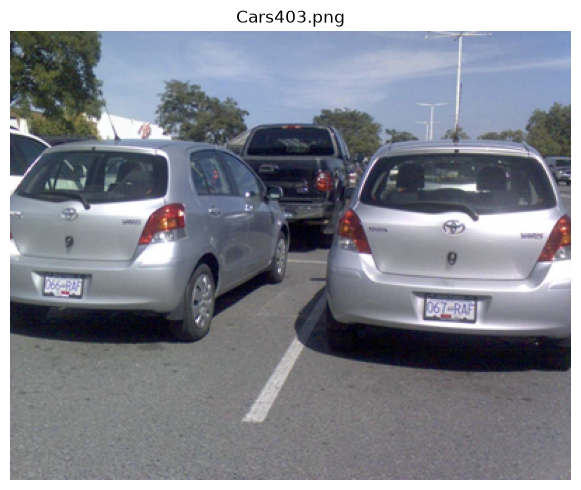

In [31]:
plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Cars403.png")
plt.axis("off")
plt.tight_layout()
plt.show()

### 2. Using Gaussian blur, smooth the image to reduce the noise

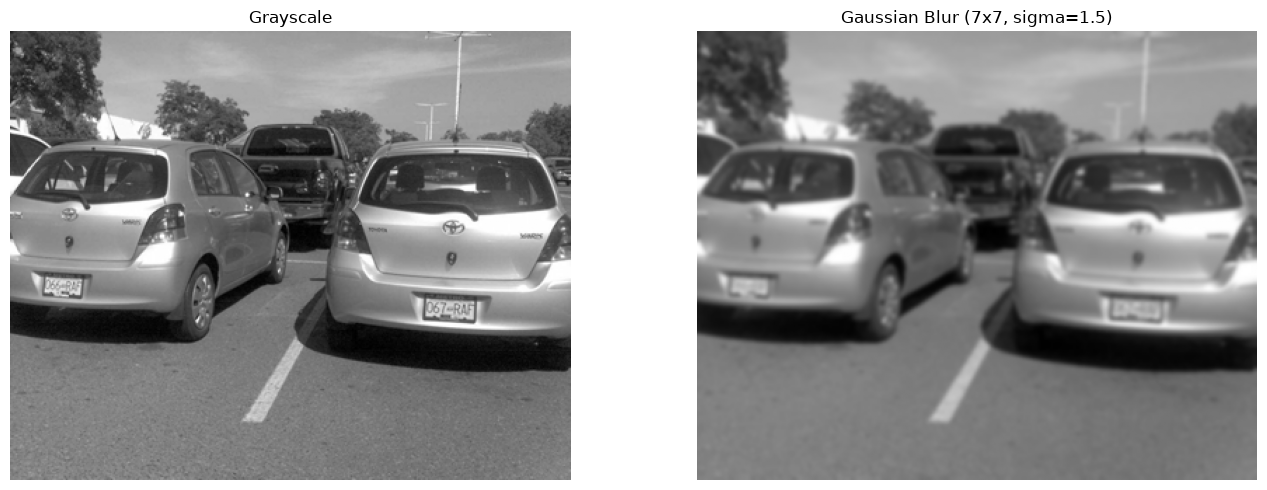

In [32]:
blur = cv2.GaussianBlur(gray, (7, 7), 1.5)  # 7x7 kernel, sigma = 1.5

cv2.imwrite(f"{OUT}/02_grayscale.png", gray)
cv2.imwrite(f"{OUT}/03_gaussian_blur.png", blur)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(gray, cmap="gray"); ax[0].set_title("Grayscale")
ax[1].imshow(blur, cmap="gray"); ax[1].set_title("Gaussian Blur (7x7, sigma=1.5)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

### 3. Perform edge detection, using cv2 for Canny algorithm

edge pixels: 4003 of 128000


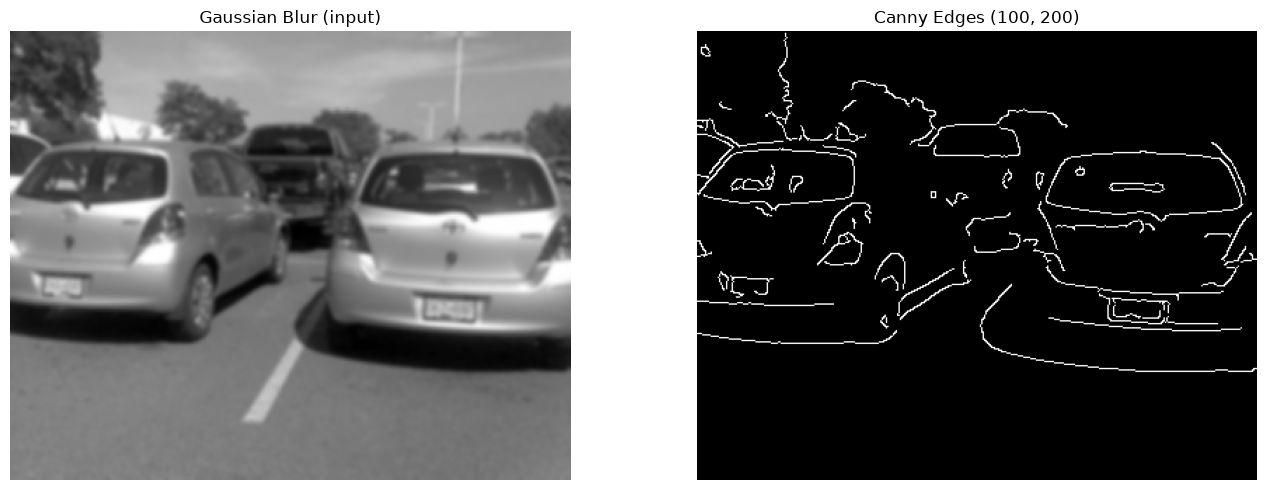

In [33]:
edges = cv2.Canny(blur, 100, 200)  # hysteresis: low=100, high=200

print("edge pixels:", int((edges > 0).sum()), "of", edges.size)
cv2.imwrite(f"{OUT}/04_canny_edges.png", edges)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(blur, cmap="gray"); ax[0].set_title("Gaussian Blur (input)")
ax[1].imshow(edges, cmap="gray"); ax[1].set_title("Canny Edges (100, 200)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

### 4. Display side by side both the original and processed image

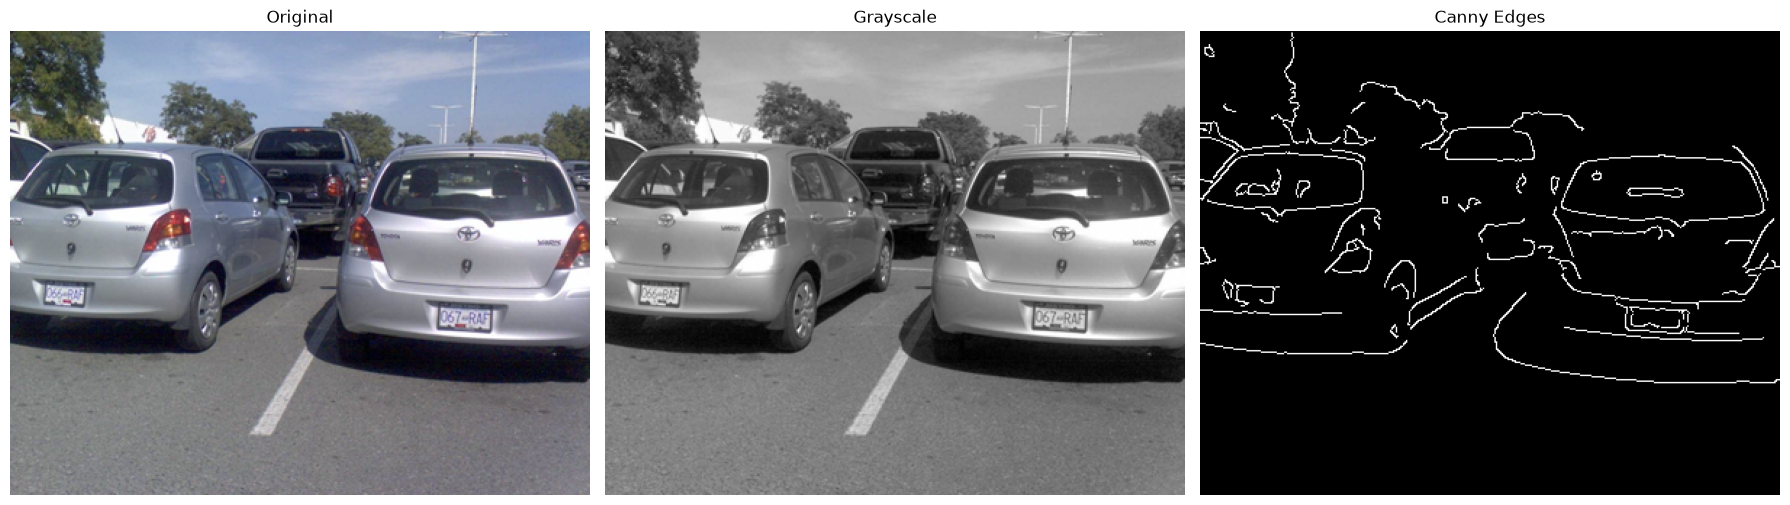

In [34]:
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title("Original")
ax[1].imshow(gray, cmap="gray");                 ax[1].set_title("Grayscale")
ax[2].imshow(edges, cmap="gray");                ax[2].set_title("Canny Edges")
for a in ax:
    a.axis("off")
plt.tight_layout()

cv2.imwrite(f"{OUT}/01_original.png", img)
fig.savefig(f"{OUT}/05_side_by_side.png", dpi=150, bbox_inches="tight")
plt.show()

## Applications

### Locating License Plates from the Edge Map

The Canny output is a binary map of intensity transitions. A license plate is just one more
such region: a closed rectangle whose border gives a strong edge ring. The detector therefore
runs in two stages. The edges **propose** plate-shaped regions, then a brightness check
**confirms** which of them are really plates. This only answers *where* a plate is, not what
is written on it, and the size limits below are tuned to this 400x320 frame rather than being
scale-invariant.

edge-stage candidates: 6
  box=(297,190, 40, 15)  mean brightness=181.0
  box=( 15,171, 40, 19)  mean brightness=165.7
  box=(110, 35, 42, 19)  mean brightness=136.2


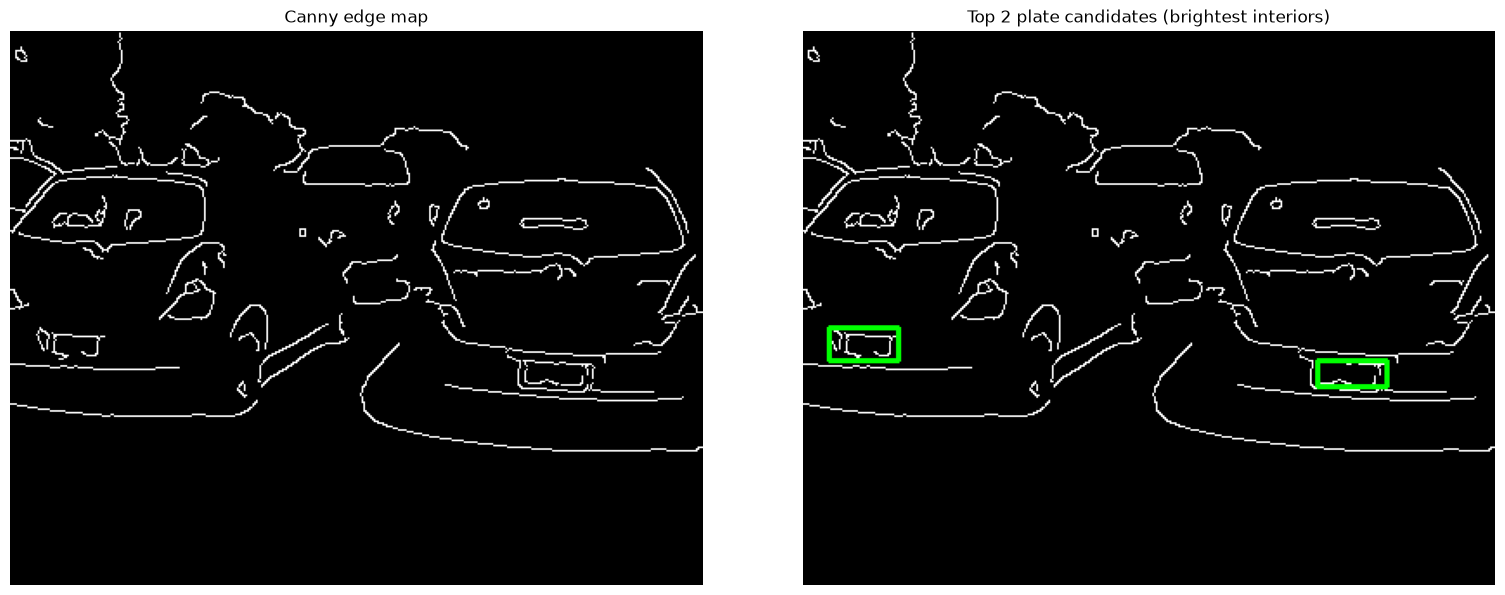

In [35]:
h, w = gray.shape
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

# Stage 1 - the edges propose plate-shaped regions.
# A small 3x3 closing seals pinholes in the border ring without fusing neighbouring shapes.
closed = cv2.morphologyEx(
    edges, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
)

# Plate geometry: wide, at least 30 px across, and small enough not to be a whole car
candidates = []
for c in cv2.findContours(closed, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)[0]:
    x, y, cw, ch = cv2.boundingRect(c)
    if 150 < cw * ch < 0.02 * h * w and 1.5 < cw / ch < 6.0 and ch >= 8 and cw >= 30:
        candidates.append((x, y, cw, ch))

# Stage 2 - confirm: a plate is retroreflective, so its interior is the brightest patch
ranked = sorted(
    candidates,
    key=lambda b: cv2.mean(hsv[b[1]:b[1] + b[3], b[0]:b[0] + b[2]])[2],
    reverse=True,
)

print("edge-stage candidates:", len(candidates))
for x, y, cw, ch in ranked[:3]:
    print("  box=({:3d},{:3d},{:3d},{:3d})  mean brightness={:5.1f}".format(
        x, y, cw, ch, cv2.mean(hsv[y:y + ch, x:x + cw])[2]))

result = cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)
for x, y, cw, ch in ranked[:2]:
    cv2.rectangle(result, (x, y), (x + cw, y + ch), (0, 255, 0), 2)

cv2.imwrite(f"{OUT}/06_license_plate_candidates.png", result)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].imshow(edges, cmap="gray"); ax[0].set_title("Canny edge map")
ax[1].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
ax[1].set_title("Top 2 plate candidates (brightest interiors)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()


## Image 2: Cars408.png

The third frame is an open highway shot. It is less dense than Cars75.png, so the blur used
for Cars403.png carries over unchanged (7x7, sigma 1.5) and the lane markings and guard rails
stay separate.

Unlike Cars75.png, the plates here *are* resolvable - roughly 26x9 px on the silver sedan and
10x5 px on the black SUV. Two changes were needed in the plate stage:

* **Local contrast instead of raw brightness.** The sedan's rear plate is dirty and shadowed,
  so its interior brightness (106) is lower than the sky and the white barriers. Subtracting
  the brightness of a ring 5 px around each candidate measures how much the region stands out
  from its surroundings, which is what actually distinguishes a plate.
* **Non-maximum suppression.** One plate frequently produces two or three overlapping
  contours, which would otherwise fill the top-N slots with duplicates of the same plate.

With both changes the detector returns exactly the two real plates.

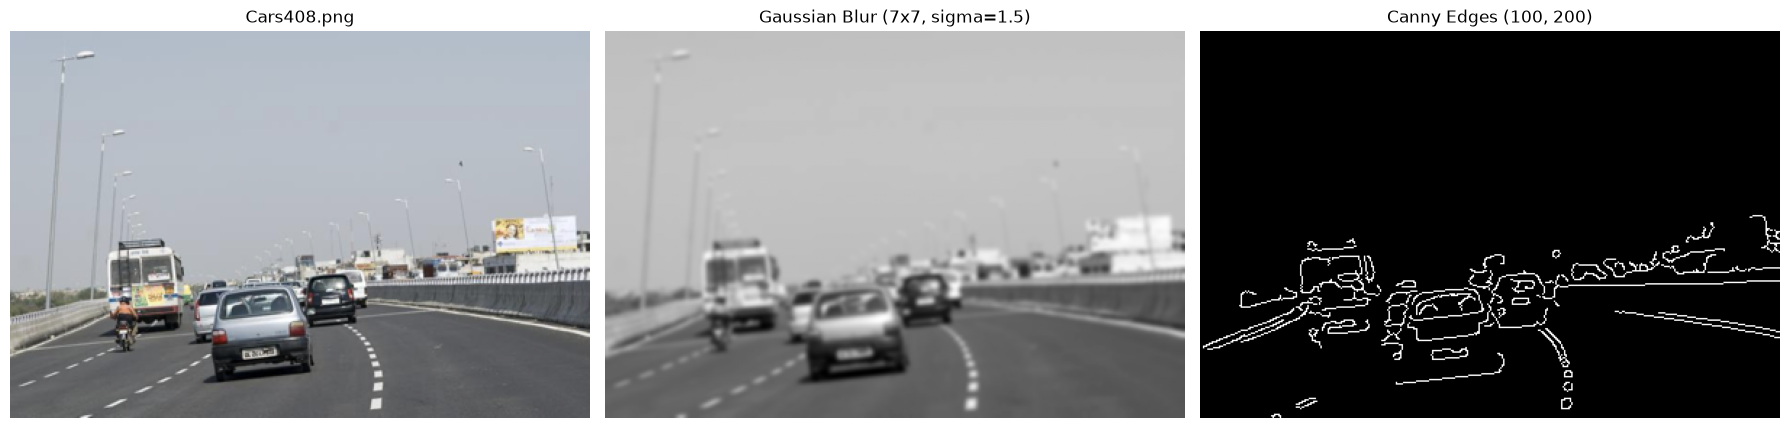

edge-stage candidates: 17
  box=(216, 184, 10, 5)  local contrast=103.0
  box=(215, 184, 13, 5)  local contrast= 98.0
  box=(160, 219, 20, 8)  local contrast= 64.2
  box=(159, 218, 26, 9)  local contrast= 50.8
  box=(97, 167, 12, 6)  local contrast= 41.5
after NMS: 14 -> top 2: [(216, 184, 10, 5), (160, 219, 20, 8)]


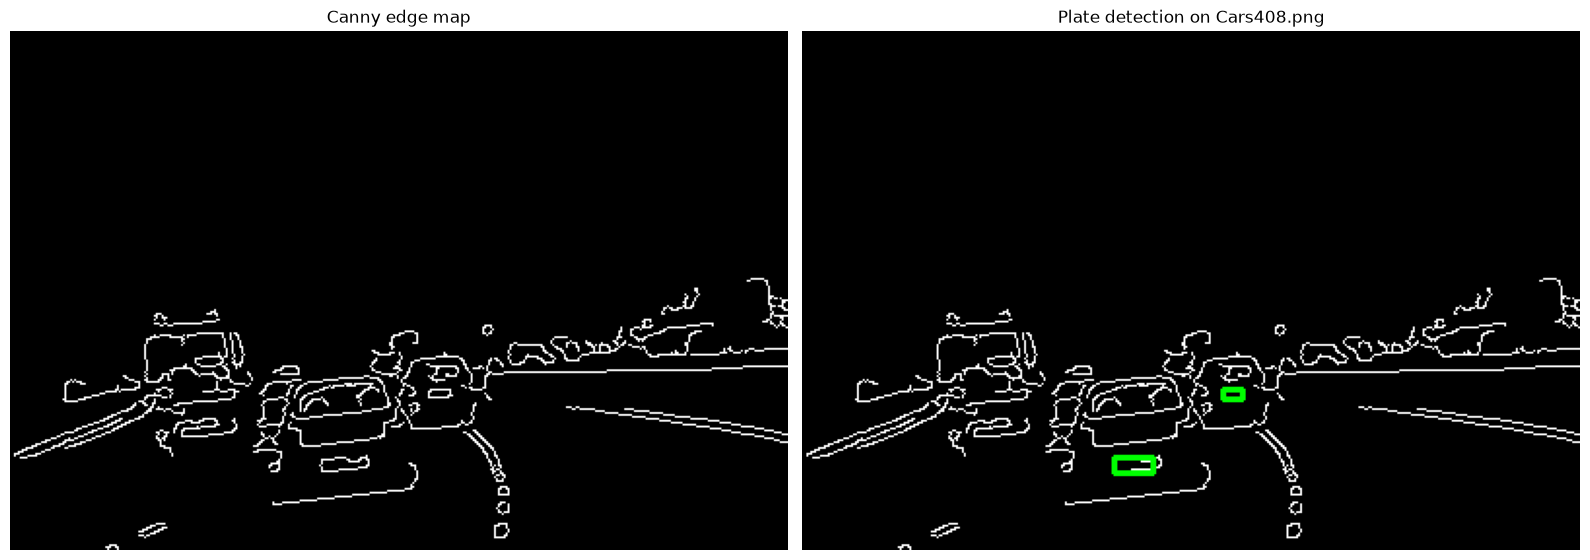

In [38]:
# ---- Whole pipeline on a third image: Cars408.png (open highway) ----
import numpy as np

IMAGE_3 = "images/Cars408.png"

img3 = cv2.imread(IMAGE_3)
gray3 = cv2.cvtColor(img3, cv2.COLOR_BGR2GRAY)

blur3 = cv2.GaussianBlur(gray3, (7, 7), 1.5)
edges3 = cv2.Canny(blur3, 100, 200)

cv2.imwrite(f"{OUT}/11_Cars408_grayscale.png", gray3)
cv2.imwrite(f"{OUT}/12_Cars408_canny.png", edges3)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(cv2.cvtColor(img3, cv2.COLOR_BGR2RGB)); ax[0].set_title("Cars408.png")
ax[1].imshow(blur3, cmap="gray"); ax[1].set_title("Gaussian Blur (7x7, sigma=1.5)")
ax[2].imshow(edges3, cmap="gray"); ax[2].set_title("Canny Edges (100, 200)")
for a in ax:
    a.axis("off")
plt.tight_layout()
fig.savefig(f"{OUT}/13_Cars408_side_by_side.png", dpi=150, bbox_inches="tight")
plt.show()


def overlap(a, b):
    """Intersection over union of two bounding boxes."""
    ax, ay, aw, ah = a
    bx, by, bw, bh = b
    ix = max(0, min(ax + aw, bx + bw) - max(ax, bx))
    iy = max(0, min(ay + ah, by + bh) - max(ay, by))
    inter = ix * iy
    return inter / (aw * ah + bw * bh - inter)


h3, w3 = gray3.shape
hsv3 = cv2.cvtColor(img3, cv2.COLOR_BGR2HSV)
closed3 = cv2.morphologyEx(edges3, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3)))

# Score each candidate by local contrast: how much brighter it is than the ring around it
scored = []
for c in cv2.findContours(closed3, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)[0]:
    x, y, cw, ch = cv2.boundingRect(c)
    if 40 < cw * ch < 0.02 * h3 * w3 and 1.5 < cw / ch < 8.0 and ch >= 5 and cw >= 10:
        inside = cv2.mean(hsv3[y:y + ch, x:x + cw])[2]
        ring = hsv3[max(0, y - 5):y + ch + 5, max(0, x - 5):x + cw + 5]
        mask = np.ones(ring.shape[:2], np.uint8)
        cv2.rectangle(mask, (5, 5), (5 + cw, 5 + ch), 0, -1)   # punch out the candidate itself
        scored.append((inside - cv2.mean(ring, mask)[2], (x, y, cw, ch)))

scored.sort(reverse=True)

print("edge-stage candidates:", len(scored))
for con, b in scored[:5]:
    print("  box={}  local contrast={:5.1f}".format(b, con))

# Non-maximum suppression: one plate gives several overlapping contours
plates3 = []
for _, b in scored:
    if all(overlap(b, p) < 0.3 for p in plates3):
        plates3.append(b)

print("after NMS:", len(plates3), "-> top 2:", plates3[:2])

result3 = cv2.cvtColor(edges3, cv2.COLOR_GRAY2BGR)
for x, y, cw, ch in plates3[:2]:
    cv2.rectangle(result3, (x, y), (x + cw, y + ch), (0, 255, 0), 2)
cv2.imwrite(f"{OUT}/14_Cars408_plate_candidates.png", result3)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].imshow(edges3, cmap="gray"); ax[0].set_title("Canny edge map")
ax[1].imshow(cv2.cvtColor(result3, cv2.COLOR_BGR2RGB))
ax[1].set_title("Plate detection on Cars408.png")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()


## 6. Flowchart and Block Diagram
Provide a simple flowchart or block diagram on how you would do your program. Explain each step or block.

## 7. Summary and Conclusions

In this activity, I was able to demonstrate an application for image processing techniques such as edge detection. In this case, I was able to use edge detection to detect and identify license plates given an image. The level of Gaussian blur greatly affects how much the edge detection works, and should be tuned depending on the image.


## 8. Learning and Challenges

The level of Gaussian blur greatly affects how much the edge detection works, and should be tuned depending on the image. Tuning was a great challenge for me as I had to do trial and error to get the values right just for the Canny edge detection to only leave the clear edges of the license plates.

## 10. Artificial Intelligence (AI) Use Disclosure Statement

I hereby declare that artificial intelligence (AI) tools were used, if applicable, in the preparation of this academic
work. The following indicates the nature and extent of AI assistance:

**Tools Used**: Github Copilot, Opencode, Claude

**Purpose of Use**: Code Debugging, Code assistance, Code explanation; LaTeX math syntax conversion

**Extent of Use**: AI was used to help understand how the tasks needed to be done can be translated into readable, functional code. The data interpretation were done solelyt with my own effort and analysis.

***
By submitting this activity, I affirm that my use of AI complies with T.I.P.'s AI usage policy and does not exceed the
permitted limits for similarity, automated content generation, or academic assistance.

I understand that any false, incomplete, or misleading disclosure may be subject to investigation in accordance
with due process and may result in sanctions for violation of existing T.I.P. policiess.